# Model Training 3 - Multilayer Perceptron (MLP)
Using tensorflow and keras

## 1. Feature Selection

In [19]:
# imports
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
# train and test data
train_df = pd.read_csv("../Data/TrainPreprocessed.csv")
test_df = pd.read_csv("../Data/TestPreprocessed.csv")

In [21]:
# function to plot model evaluation
sns.set_theme(style="whitegrid")

def plot_model_evaluation(y_true, y_pred, title="Model Evaluation"):
    """
    Plot residual, prediction, and ground truth diagnostics for regression models.
    
    Parameters:
        y_true (array-like): Ground truth values
        y_pred (array-like): Model predictions
        title (str): Title of the overall plot
    """
    y_true = np.array(y_true).flatten()
    y_pred = np.array(y_pred).flatten()
    residuals = y_pred - y_true

    # Create figure layout
    fig, axs = plt.subplots(3, 2, figsize=(14, 14))
    fig.suptitle(title, fontsize=16)

    # 1. Residual Histogram
    sns.histplot(residuals, bins=60, ax=axs[0, 0], color="C0")
    axs[0, 0].set_title("Residual Histogram")
    axs[0, 0].set_xlabel("Residual")
    axs[0, 0].set_ylabel("Density")

    # 2. Ground Truth Histogram
    sns.histplot(y_true, bins=60, ax=axs[0, 1], color="C0")
    axs[0, 1].set_title("Ground Truth Histogram")
    axs[0, 1].set_xlabel("Ground truth")
    axs[0, 1].set_ylabel("Density")

    # 3. Prediction Histogram
    sns.histplot(y_pred, bins=60, ax=axs[1, 0], color="C0")
    axs[1, 0].set_title("Prediction Histogram")
    axs[1, 0].set_xlabel("Prediction")
    axs[1, 0].set_ylabel("Density")

    # 4. Ground Truth vs Predictions (binned)
    df_gt_pred = pd.DataFrame({"ground_truth": y_true, "prediction": y_pred})
    df_gt_pred["gt_bin"] = pd.cut(df_gt_pred["ground_truth"], bins=30)
    binned_gt = df_gt_pred.groupby("gt_bin", observed=False).mean(numeric_only=True)

    axs[1, 1].plot(binned_gt["ground_truth"], binned_gt["prediction"], label="Prediction", color="darkorange")
    axs[1, 1].plot(binned_gt["ground_truth"], binned_gt["ground_truth"], linestyle="--", color="C0", label="Ideal")
    axs[1, 1].set_title("Ground Truth vs Predictions (Binned)")
    axs[1, 1].set_xlabel("Ground Truth")
    axs[1, 1].set_ylabel("Prediction")
    axs[1, 1].legend()

    # 5. Predictions vs Residual (binned)
    df_pred_res = pd.DataFrame({"prediction": y_pred, "residual": residuals})
    df_pred_res["pred_bin"] = pd.cut(df_pred_res["prediction"], bins=30)
    binned_pred = df_pred_res.groupby("pred_bin", observed=False).mean(numeric_only=True)

    axs[2, 0].plot(binned_pred["prediction"], binned_pred["residual"], color="darkorange")
    axs[2, 0].axhline(0, linestyle="--", color="C0")
    axs[2, 0].set_title("Predictions vs Residual (Binned)")
    axs[2, 0].set_xlabel("Prediction")
    axs[2, 0].set_ylabel("Residual")

    # 6. Ground Truth vs Residual (binned)
    df_gt_res = pd.DataFrame({"ground_truth": y_true, "residual": residuals})
    df_gt_res["gt_bin"] = pd.cut(df_gt_res["ground_truth"], bins=30)
    binned_gt_res = df_gt_res.groupby("gt_bin", observed=False).mean(numeric_only=True)

    axs[2, 1].plot(binned_gt_res["ground_truth"], binned_gt_res["residual"], color="darkorange")
    axs[2, 1].axhline(0, linestyle="--", color="C0")
    axs[2, 1].set_title("Ground Truth vs Residual (Binned)")
    axs[2, 1].set_xlabel("Ground Truth")
    axs[2, 1].set_ylabel("Residual")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


In [ ]:
# Function to compute permutation importance for a model
def compute_permutation_importance(model, X, y, model_name):
    # Calculate the baseline RMSE 
    baseline_rmse = np.sqrt(mean_squared_error(y, model.predict(X)))
    print(f"{model_name} - Baseline RMSE: {baseline_rmse:.2f}")
    
    importances = {}
    X_copy = X.copy() # Create a copy of the input features to avoid modifying the original data
    
    for col in X.columns:
        # Shuffle the values of the current feature -> simulates a scenario where the feature is not informative
        X_shuffled = X_copy.copy()
        X_shuffled[col] = np.random.permutation(X_shuffled[col])
        
        # Predict and measure new rsme
        y_pred_shuffled = model.predict(X_shuffled)
        rmse = np.sqrt(mean_squared_error(y, y_pred_shuffled))
        
        # Compute the importance as the difference between the shuffled RMSE and the baseline RMSE
        importances[col] = rmse - baseline_rmse

    # Convert the importances dictionary to a DataFrame, sort by importance, and return
    return pd.DataFrame.from_dict(importances, orient='index', columns=['Importance']).sort_values(by='Importance', ascending=False)

### Model 1.1 - using all default features

In [22]:
# define features and labels fpr this model
X_train = train_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME", "DAYS_SINCE_LAUNCH"])
y_train = train_df["LIFETIME"]

X_test = test_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME", "DAYS_SINCE_LAUNCH"])
y_test = test_df["LIFETIME"]

In [23]:
# define model architecture
model1_1 = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="relu")  # ensure output is non-negative
])

In [24]:
# compile model
model1_1.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[keras.metrics.RootMeanSquaredError()]
)

In [25]:
# train model
early_stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model1_1.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 1s 994us/step - loss: 18856120.0000 - root_mean_squared_error: 4341.9785 - val_loss: 19727880.0000 - val_root_mean_squared_error: 4441.6079
Epoch 2/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 690us/step - loss: 18842650.0000 - root_mean_squared_error: 4340.3018 - val_loss: 19330046.0000 - val_root_mean_squared_error: 4396.5947
Epoch 3/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 652us/step - loss: 18553378.0000 - root_mean_squared_error: 4307.1816 - val_loss: 19441216.0000 - val_root_mean_squared_error: 4409.2192
Epoch 4/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 681us/step - loss: 18149202.0000 - root_mean_squared_error: 4259.4072 - val_loss: 19802988.0000 - val_root_mean_squared_error: 4450.0547
Epoch 5/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 683us/step - loss: 18400468.0000 - root_mean_squared_error: 4289.3560 - val_loss: 19256190.0000 - val_root_mean_squared_error: 4388.1875
Epoch 6/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 646us/step - loss: 19057862.0000 - root_mean_square

In [26]:
# evaluate model
loss, rmse = model1_1.evaluate(X_test, y_test)
print("Test RMSE:", rmse)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 575us/step - loss: 1506653.1250 - root_mean_squared_error: 1225.9469
Test RMSE: 1224.6207275390625


153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 553us/step


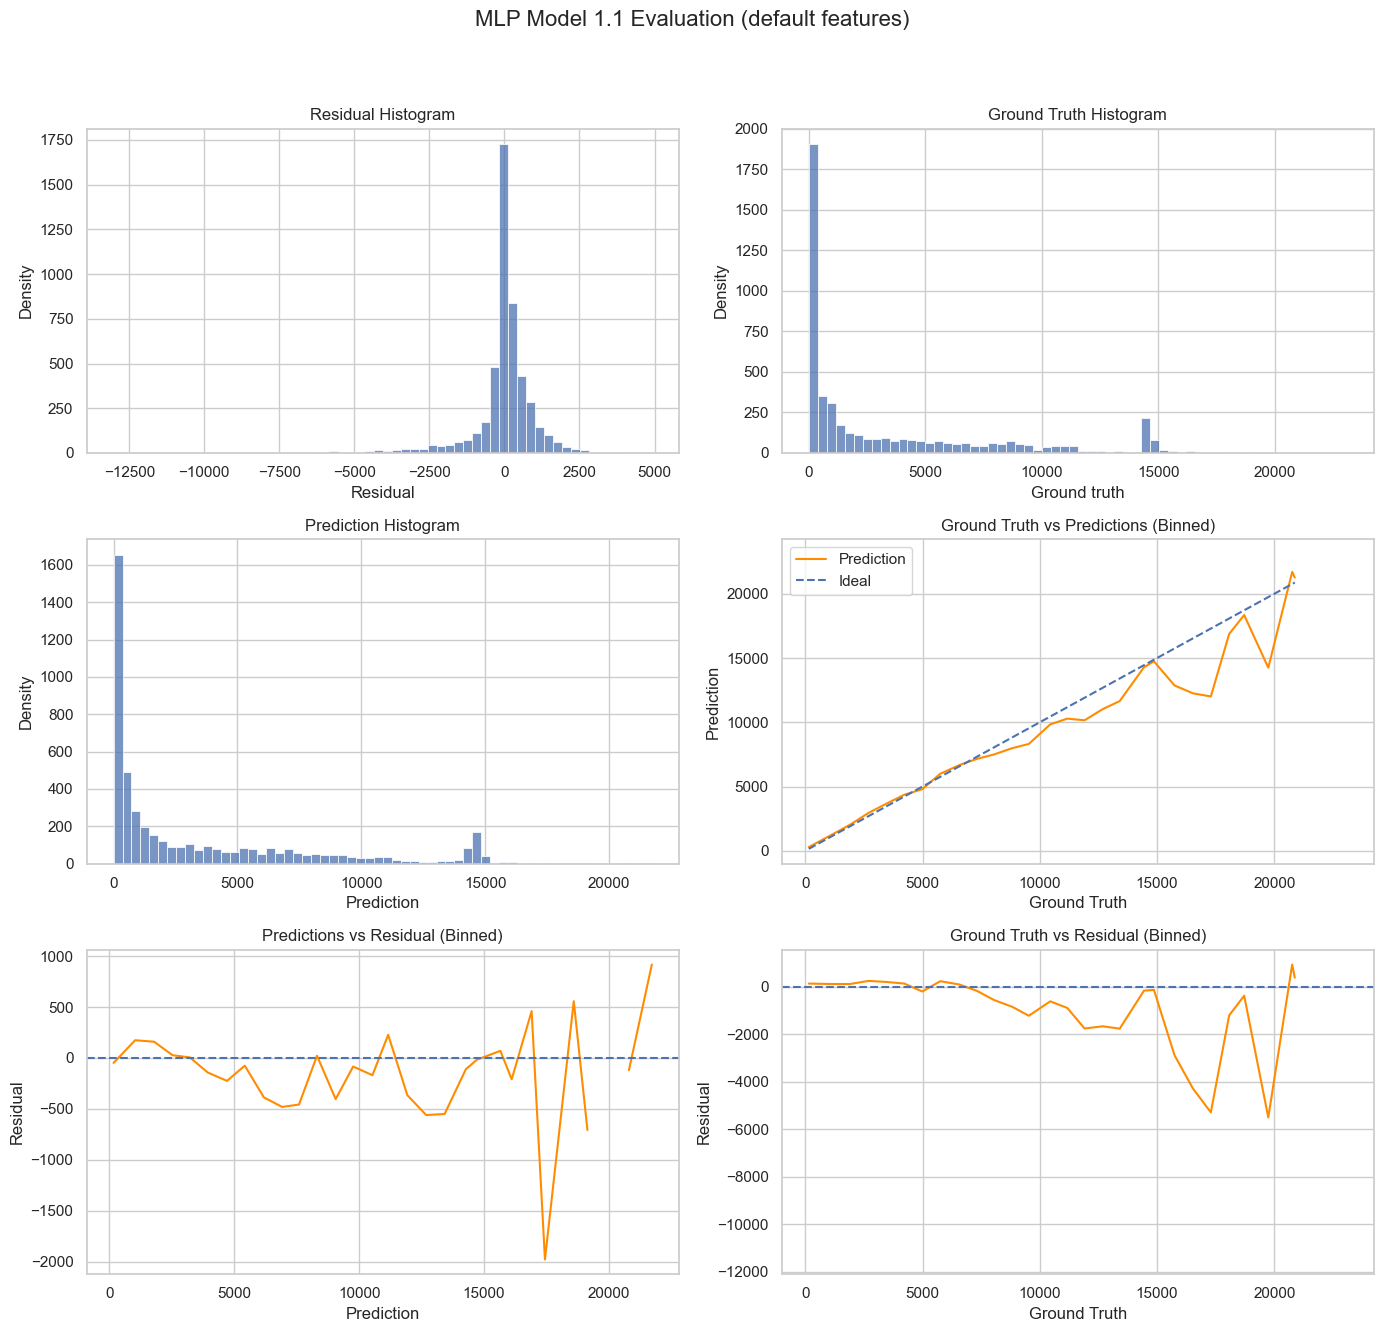

In [27]:
# plot model evaluation
y_pred1_1 = model1_1.predict(X_test)
plot_model_evaluation(y_test, y_pred1_1, title="MLP Model 1.1 Evaluation (default features)")

In [30]:
# save model
model1_1.save("../Models/MLP1_1.keras")

### Model 1.2 - Including engineered feature 'DAYS_SINCE_LAUNCH'

In [88]:
# define features and labels fpr this model
X_train_1_2 = train_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_train_1_2 = train_df["LIFETIME"]

X_test_1_2 = test_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_test_1_2 = test_df["LIFETIME"]

In [ ]:
# define model architecture
model1_2 = keras.Sequential([
    layers.Input(shape=(X_train_1_2.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="relu")  # ensure output is non-negative
])

In [33]:
# compile model
model1_2.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[keras.metrics.RootMeanSquaredError()]
)

In [34]:
# train model
early_stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model1_2.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 1s 839us/step - loss: 18282808.0000 - root_mean_squared_error: 4275.5044 - val_loss: 19360088.0000 - val_root_mean_squared_error: 4400.0098
Epoch 2/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 818us/step - loss: 19410776.0000 - root_mean_squared_error: 4405.3042 - val_loss: 19686150.0000 - val_root_mean_squared_error: 4436.9077
Epoch 3/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 683us/step - loss: 18500682.0000 - root_mean_squared_error: 4300.8120 - val_loss: 19309254.0000 - val_root_mean_squared_error: 4394.2295
Epoch 4/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 658us/step - loss: 18396842.0000 - root_mean_squared_error: 4288.0024 - val_loss: 19325110.0000 - val_root_mean_squared_error: 4396.0332
Epoch 5/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 656us/step - loss: 18588772.0000 - root_mean_squared_error: 4311.3003 - val_loss: 19199930.0000 - val_root_mean_squared_error: 4381.7725
Epoch 6/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 656us/step - loss: 18323016.0000 - root_mean_square

In [35]:
# evaluate model
loss, rmse = model1_2.evaluate(X_test, y_test)
print("Test RMSE:", rmse)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 1229860.7500 - root_mean_squared_error: 1106.6384
Test RMSE: 1088.0537109375


153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 496us/step


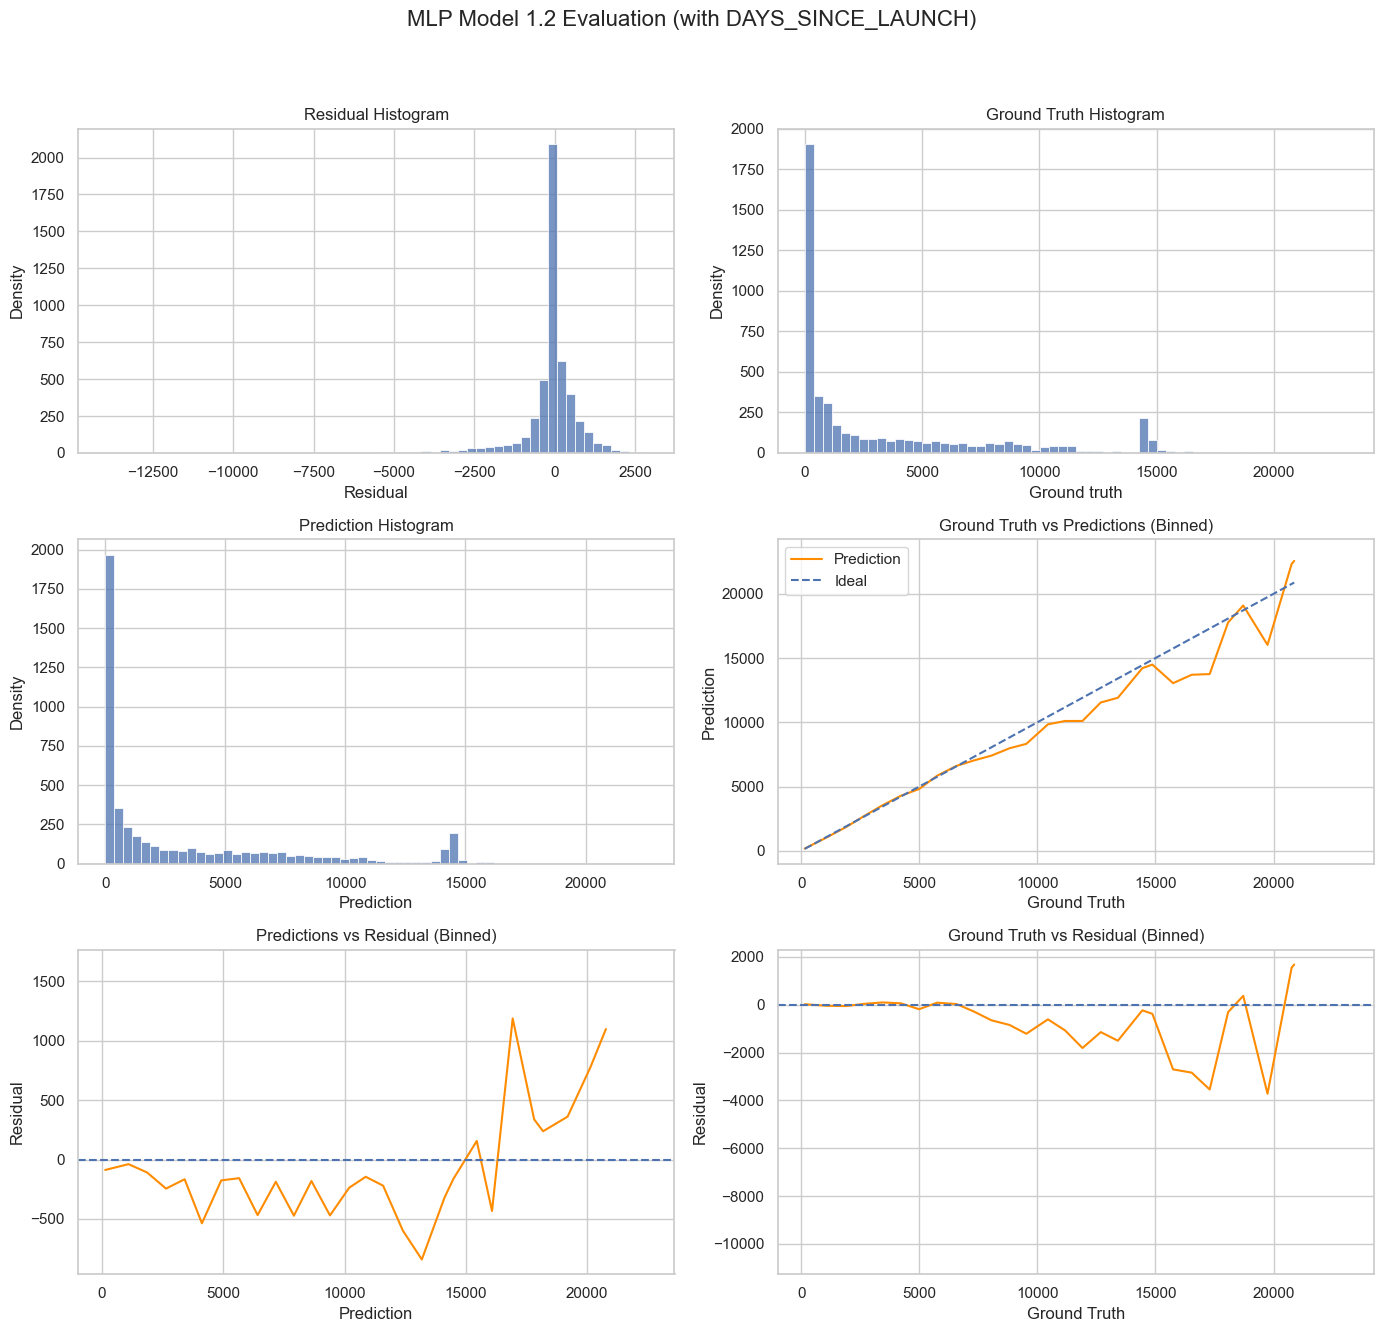

In [36]:
# plot model evaluation
y_pred1_2 = model1_2.predict(X_test)
plot_model_evaluation(y_test, y_pred1_2, title="MLP Model 1.2 Evaluation (with DAYS_SINCE_LAUNCH)")

In [107]:
# calculate feature importances
importances_1_2 = compute_permutation_importance(model1_2, X_test_1_2, y_test_1_2, model_name="Model 1.2")
importances_1_2.head(20)

,Importance
DAYS_SINCE_LAUNCH,2946.604525
LAUNCH_YEAR,1478.676976
EPOCH_YEAR,801.054232
NORAD_CAT_ID,504.820307
MEAN_MOTION,281.556887
REV_AT_EPOCH,152.275366
PERIAPSIS,72.253301
PERIOD,22.141485
COUNTRY_US,17.865137
INCLINATION,16.835480


In [37]:
# save model
model1_2.save("../Models/MLP1_2.keras")

### Model 1.3 - Using Remaining Lifetime as Label

In [89]:
# define features and labels for this model
X_train_1_3 = train_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_train_1_3 = train_df["REMAINING_LIFETIME"]

X_test_1_3 = test_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_test_1_3 = test_df["REMAINING_LIFETIME"]

In [ ]:
# define model architecture
model1_3 = keras.Sequential([
    layers.Input(shape=(X_train_1_3.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="relu")  # ensure output is non-negative
])

In [56]:
# compile model
model1_3.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[keras.metrics.RootMeanSquaredError()]
)

In [57]:
# train model
early_stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model1_3.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 1s 826us/step - loss: 1770572.0000 - root_mean_squared_error: 1329.3726 - val_loss: 1734951.0000 - val_root_mean_squared_error: 1317.1754
Epoch 2/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 653us/step - loss: 1764463.6250 - root_mean_squared_error: 1327.2865 - val_loss: 1734951.0000 - val_root_mean_squared_error: 1317.1754
Epoch 3/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 864us/step - loss: 1746816.3750 - root_mean_squared_error: 1320.7660 - val_loss: 1734951.0000 - val_root_mean_squared_error: 1317.1754
Epoch 4/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 665us/step - loss: 1776204.8750 - root_mean_squared_error: 1332.1805 - val_loss: 1734951.0000 - val_root_mean_squared_error: 1317.1754
Epoch 5/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 675us/step - loss: 1766669.5000 - root_mean_squared_error: 1328.2870 - val_loss: 1734951.0000 - val_root_mean_squared_error: 1317.1754
Epoch 6/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 648us/step - loss: 1751962.3750 - root_mean_squared_error: 13

In [58]:
# evaluate model
loss, rmse = model1_3.evaluate(X_test, y_test)
print("Test RMSE:", rmse)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 572us/step - loss: 1966955.3750 - root_mean_squared_error: 1399.8456
Test RMSE: 1372.8896484375


153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 464us/step


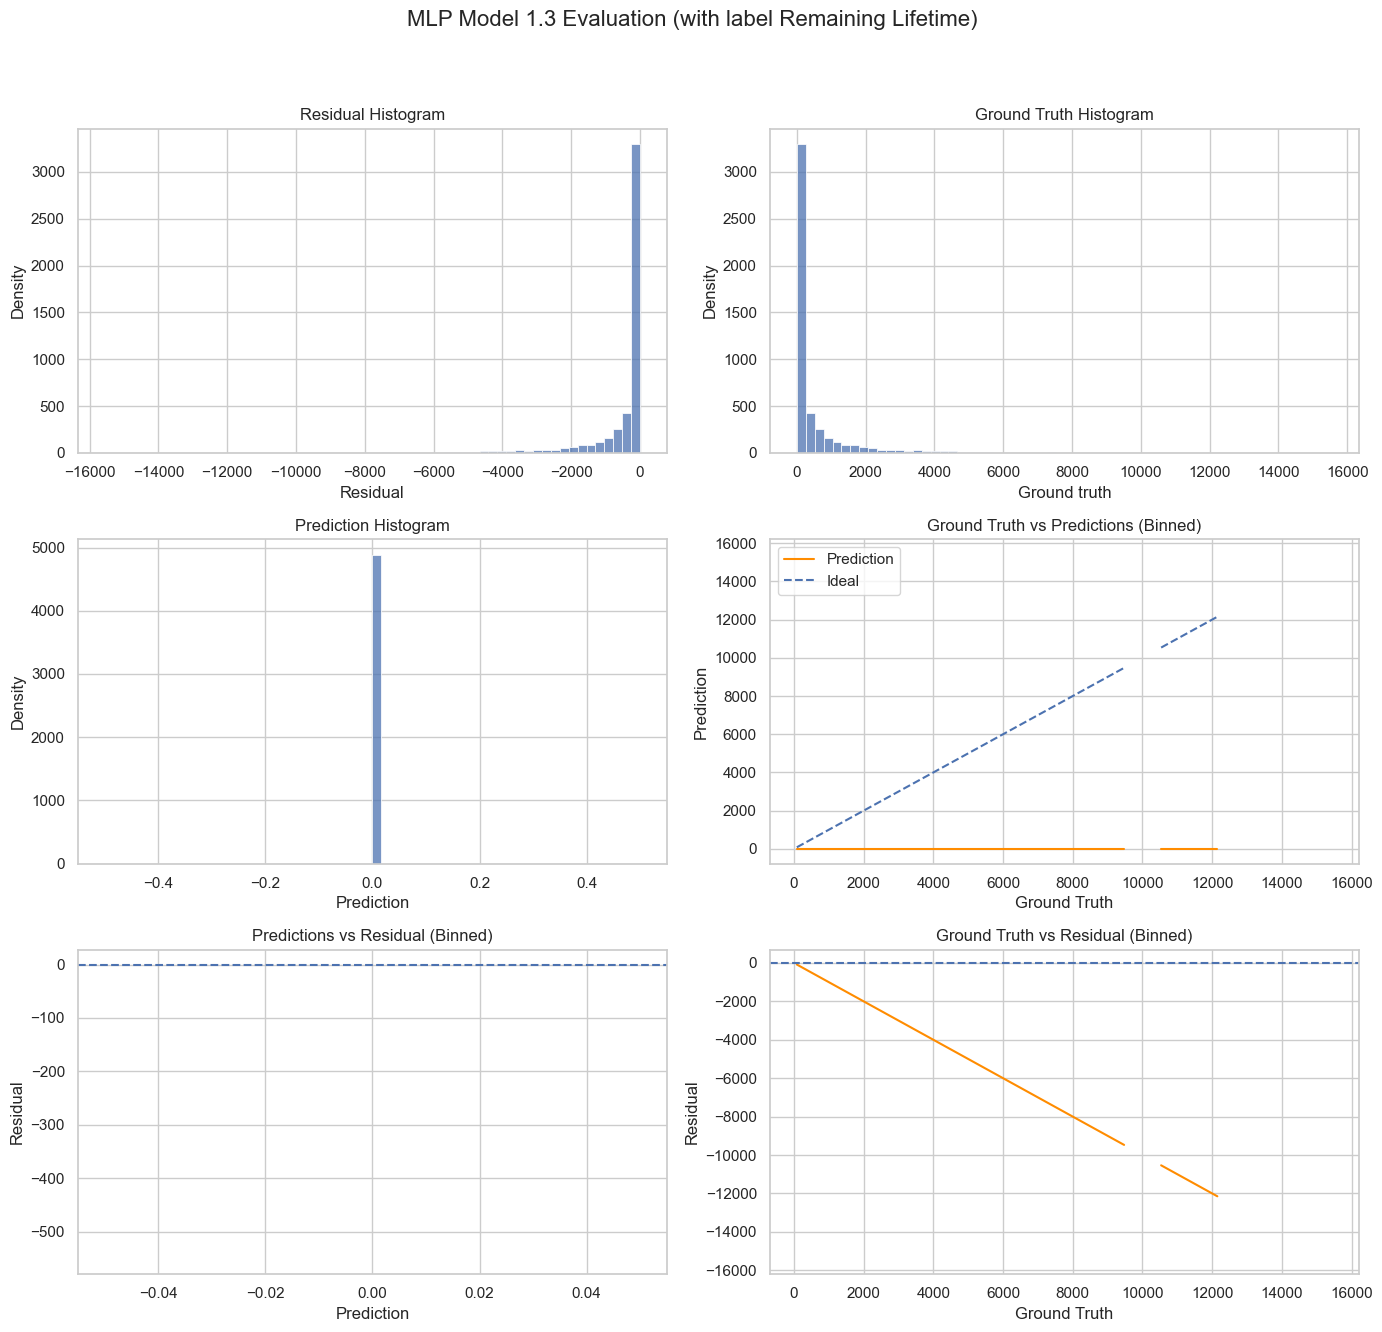

In [59]:
# plot model evaluation
y_pred1_3 = model1_3.predict(X_test)
plot_model_evaluation(y_test, y_pred1_3, title="MLP Model 1.3 Evaluation (with label Remaining Lifetime)")

#### Predictions are really bad, so we will refine the architecture to adapt to the new label
All predictions are 0, the ReLU output neuron seems be "dead" — it never gets activated <br>
-> Change last layer from relu to linear activation function


In [ ]:
# define model architecture (change last layer to linear activation)
model1_3 = keras.Sequential([
    layers.Input(shape=(X_train_1_3.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="linear")  # change to linear 
])

In [111]:
# compile model
model1_3.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[keras.metrics.RootMeanSquaredError()]
)

In [112]:
# train model
early_stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model1_3.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 1824041.7500 - root_mean_squared_error: 1338.0947 - val_loss: 2145083.0000 - val_root_mean_squared_error: 1464.6102
Epoch 2/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 907us/step - loss: 1687821.7500 - root_mean_squared_error: 1298.5839 - val_loss: 1583244.5000 - val_root_mean_squared_error: 1258.2704
Epoch 3/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 689us/step - loss: 1693236.8750 - root_mean_squared_error: 1297.9865 - val_loss: 1585246.0000 - val_root_mean_squared_error: 1259.0656
Epoch 4/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 649us/step - loss: 1566247.8750 - root_mean_squared_error: 1249.5504 - val_loss: 1561699.2500 - val_root_mean_squared_error: 1249.6797
Epoch 5/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 646us/step - loss: 1640698.2500 - root_mean_squared_error: 1279.8398 - val_loss: 1542593.7500 - val_root_mean_squared_error: 1242.0120
Epoch 6/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 822us/step - loss: 1503791.6250 - root_mean_squared_error: 1224

In [113]:
# evaluate model
loss, rmse = model1_3.evaluate(X_test, y_test)
print("Test RMSE:", rmse)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 549us/step - loss: 1243508.1250 - root_mean_squared_error: 1112.7285
Test RMSE: 1086.0765380859375


153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


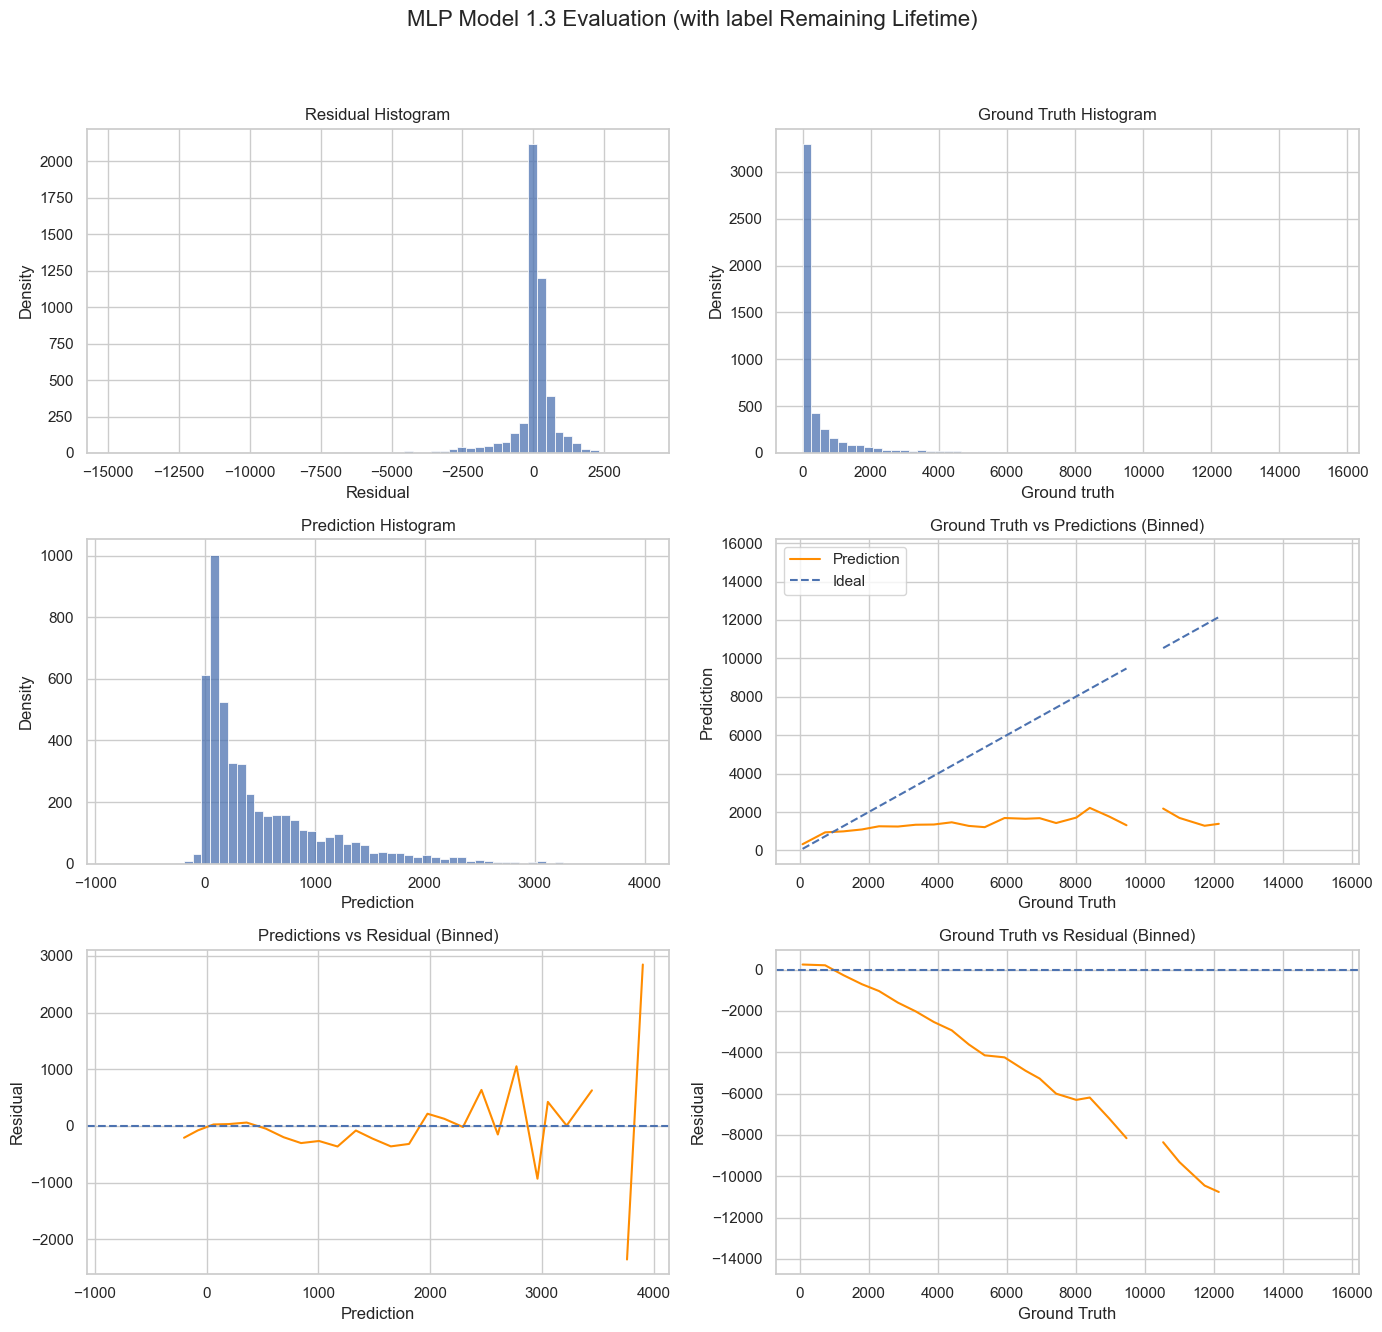

In [114]:
# plot model evaluation
y_pred1_3 = model1_3.predict(X_test)
plot_model_evaluation(y_test, y_pred1_3, title="MLP Model 1.3 Evaluation (with label Remaining Lifetime)")

In [115]:
# calculate feature importances
importances_1_3 = compute_permutation_importance(model1_3, X_test_1_3, y_test_1_3, model_name="Model 1.3")
importances_1_3.head(20)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 383us/step
Model 1.3 - Baseline RMSE: 1086.08
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 332us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 316us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 338us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 321us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 325us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 351us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 358us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 886us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 350us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 319us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 446us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 326us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 320us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 330us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 329us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 318us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 322us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 314us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 323us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 322us/step
153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 325us/step
153/153 ━━━━━━━━━━━

,Importance
REV_AT_EPOCH,66.051169
MEAN_MOTION,32.265427
PERIAPSIS,26.880278
DAYS_SINCE_LAUNCH,14.510180
MEAN_MOTION_DOT,8.446873
SITE_TSC,7.322061
BSTAR,7.220653
INCLINATION,6.296623
NORAD_CAT_ID,5.728503
COUNTRY_PRC,4.892411


In [116]:
# save model
model1_3.save("../Models/MLP1_3.keras")

### Model 1.4 - Using Lifetime again, but removing features related to epoch
Days since Launch, Revolutions at Epoch, Epoch Year & Epoch Month

In [ ]:
# define features and labels fpr this model
X_train_1_4 = train_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME", "DAYS_SINCE_LAUNCH", "REV_AT_EPOCH", "EPOCH_YEAR", "EPOCH_MONTH"])
y_train_1_4 = train_df["LIFETIME"]

X_test_1_4 = test_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME", "DAYS_SINCE_LAUNCH", "REV_AT_EPOCH", "EPOCH_YEAR", "EPOCH_MONTH"])
y_test_1_4 = test_df["LIFETIME"]

In [ ]:
# define model architecture
model1_4 = keras.Sequential([
    layers.Input(shape=(X_train_1_4.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="relu")  # ensure output is non-negative
])

In [74]:
# compile model
model1_4.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[keras.metrics.RootMeanSquaredError()]
)

In [75]:
# train model
early_stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model1_4.fit(
    X_train_1_4, y_train_1_4,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 1s 853us/step - loss: 19454564.0000 - root_mean_squared_error: 4407.8179 - val_loss: 19460682.0000 - val_root_mean_squared_error: 4411.4263
Epoch 2/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 724us/step - loss: 18748196.0000 - root_mean_squared_error: 4329.7900 - val_loss: 19377920.0000 - val_root_mean_squared_error: 4402.0361
Epoch 3/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 870us/step - loss: 18041692.0000 - root_mean_squared_error: 4246.4951 - val_loss: 19427296.0000 - val_root_mean_squared_error: 4407.6406
Epoch 4/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 660us/step - loss: 18741382.0000 - root_mean_squared_error: 4328.8267 - val_loss: 19384482.0000 - val_root_mean_squared_error: 4402.7812
Epoch 5/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 654us/step - loss: 18690930.0000 - root_mean_squared_error: 4322.9897 - val_loss: 20544700.0000 - val_root_mean_squared_error: 4532.6260
Epoch 6/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 774us/step - loss: 17813712.0000 - root_mean_square

In [76]:
# evaluate model
loss, rmse = model1_4.evaluate(X_test_1_4, y_test_1_4)
print("Test RMSE:", rmse)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 578us/step - loss: 6030888.0000 - root_mean_squared_error: 2454.2295
Test RMSE: 2474.611083984375


153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 370us/step


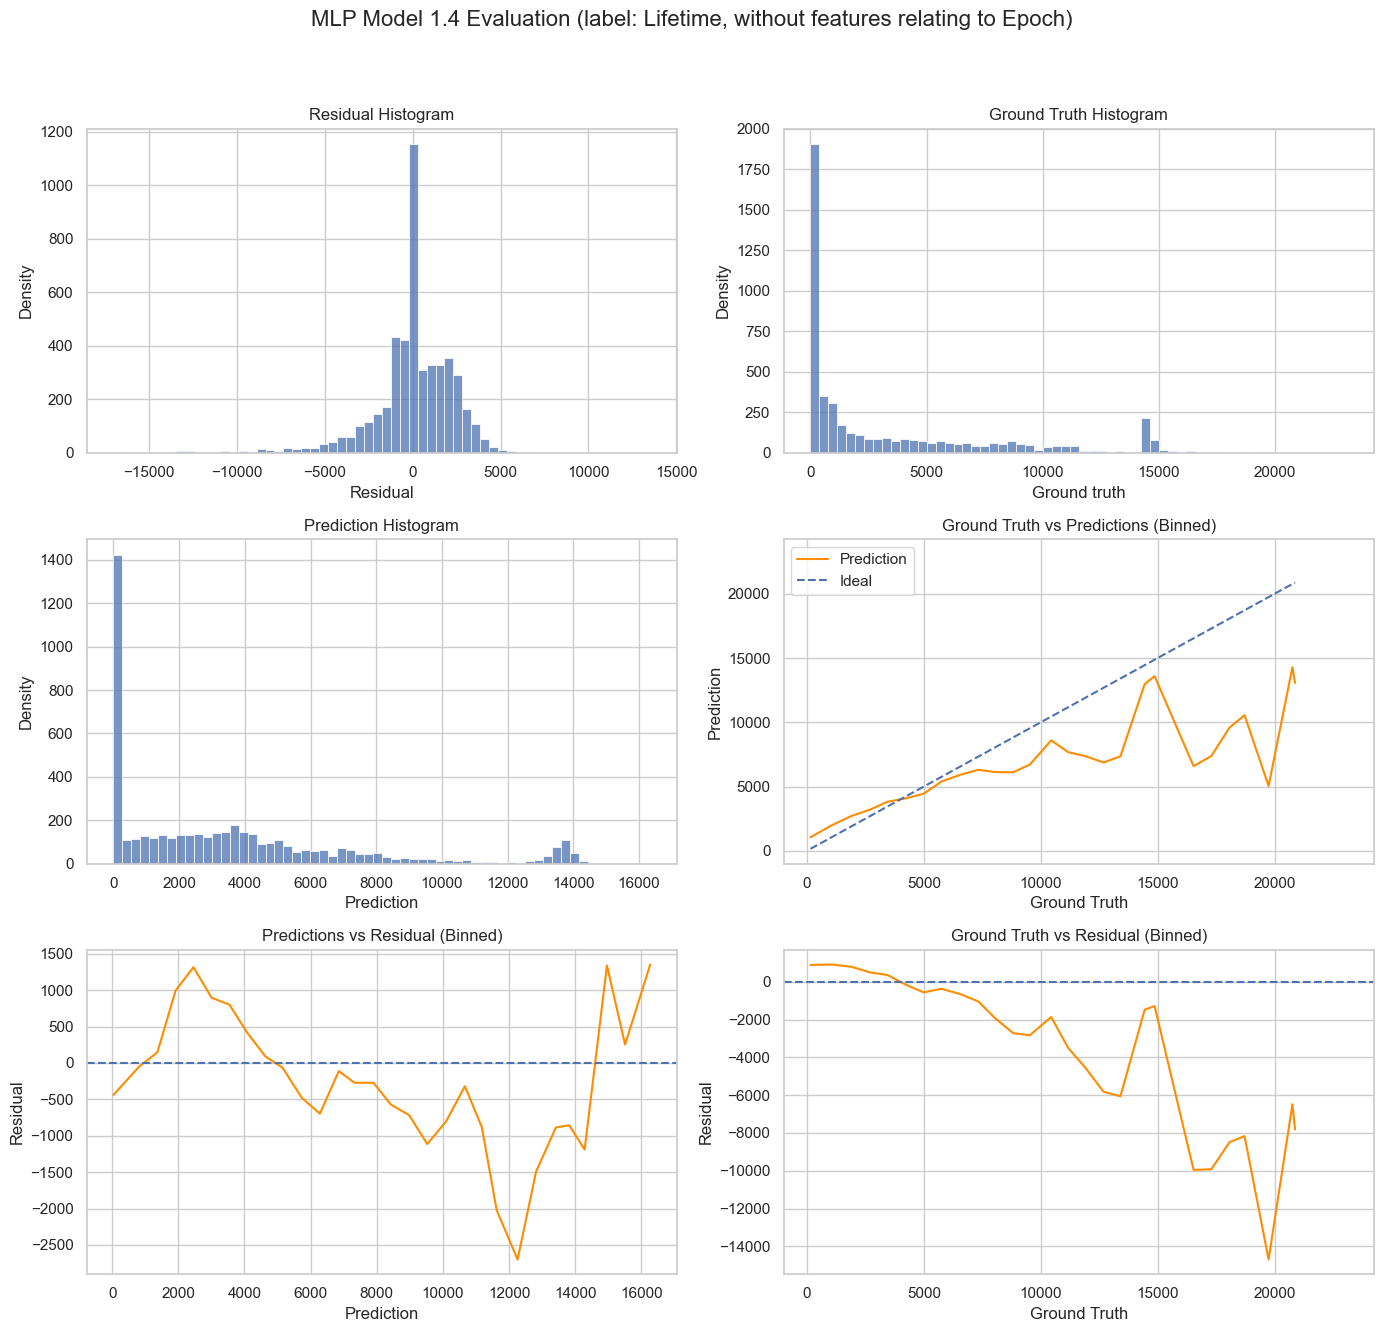

In [78]:
# plot model evaluation
y_pred1_4 = model1_4.predict(X_test_1_4)
plot_model_evaluation(y_test_1_4, y_pred1_4, title="MLP Model 1.4 Evaluation (label: Lifetime, without features relating to Epoch)")

In [86]:
# save model
model1_4.save("../Models/MLP1_4.keras")

## 2. Data Balancing
Continue using remaining Lifetime as label

### Model 2.1 - sample weights
Use inverse frequency based sample weights

In [140]:
# compute inverse frequency weights of years
train_sw_df = train_df.copy()
train_sw_df["REMAINING_LIFETIME_YEARS"] = (train_sw_df["REMAINING_LIFETIME"] / 365).round(0).astype(int)
year_freq = train_sw_df["REMAINING_LIFETIME_YEARS"].value_counts()
year_freq = year_freq / len(train_sw_df) # normalize to get frequency proportion

sample_weights = train_sw_df["REMAINING_LIFETIME_YEARS"].map(lambda y: 1 / year_freq[y]).values
sample_weights = np.log1p(sample_weights) # compress extremes
sample_weights = sample_weights / sample_weights.mean() # normalize

# drop column 
train_sw_df.drop(columns=['REMAINING_LIFETIME_YEARS'], inplace=True)

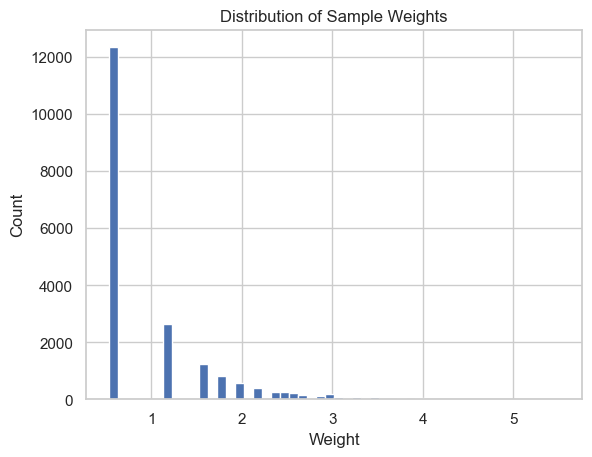

In [141]:
# visualize distribution of sample weights
import matplotlib.pyplot as plt
plt.hist(sample_weights, bins=50)
plt.title("Distribution of Sample Weights")
plt.xlabel("Weight")
plt.ylabel("Count")
plt.show()

In [142]:
# define features and labels for this model
X_train_2_1 = train_sw_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_train_2_1 = train_sw_df["REMAINING_LIFETIME"]

X_test_2_1 = test_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_test_2_1 = test_df["REMAINING_LIFETIME"]

In [ ]:
# define model architecture 
model2_1 = keras.Sequential([
    layers.Input(shape=(X_train_2_1.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="linear")  
])

In [144]:
# compile model
model2_1.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[keras.metrics.RootMeanSquaredError()]
)

In [145]:
# train model
early_stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model2_1.fit(
    X_train_2_1, y_train_2_1,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1, 
    sample_weight=sample_weights # specify sample weight array
)

Epoch 1/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 4830563.0000 - root_mean_squared_error: 1401.4169 - val_loss: 5135291.0000 - val_root_mean_squared_error: 1337.2675
Epoch 2/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 752us/step - loss: 4840694.5000 - root_mean_squared_error: 1385.5538 - val_loss: 5175282.0000 - val_root_mean_squared_error: 1289.5673
Epoch 3/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 972us/step - loss: 5000110.5000 - root_mean_squared_error: 1400.1384 - val_loss: 5180076.5000 - val_root_mean_squared_error: 1506.5986
Epoch 4/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 680us/step - loss: 5511450.0000 - root_mean_squared_error: 1472.0875 - val_loss: 5140578.0000 - val_root_mean_squared_error: 1472.1072
Epoch 5/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 871us/step - loss: 5001093.0000 - root_mean_squared_error: 1406.8428 - val_loss: 5077546.5000 - val_root_mean_squared_error: 1398.6901
Epoch 6/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 680us/step - loss: 5188799.0000 - root_mean_squared_error: 1431

In [146]:
# evaluate model
loss, rmse = model2_1.evaluate(X_test_2_1, y_test_2_1)
print("Test RMSE:", rmse)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 502us/step - loss: 1518728.6250 - root_mean_squared_error: 1231.1285
Test RMSE: 1211.953857421875


153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 493us/step


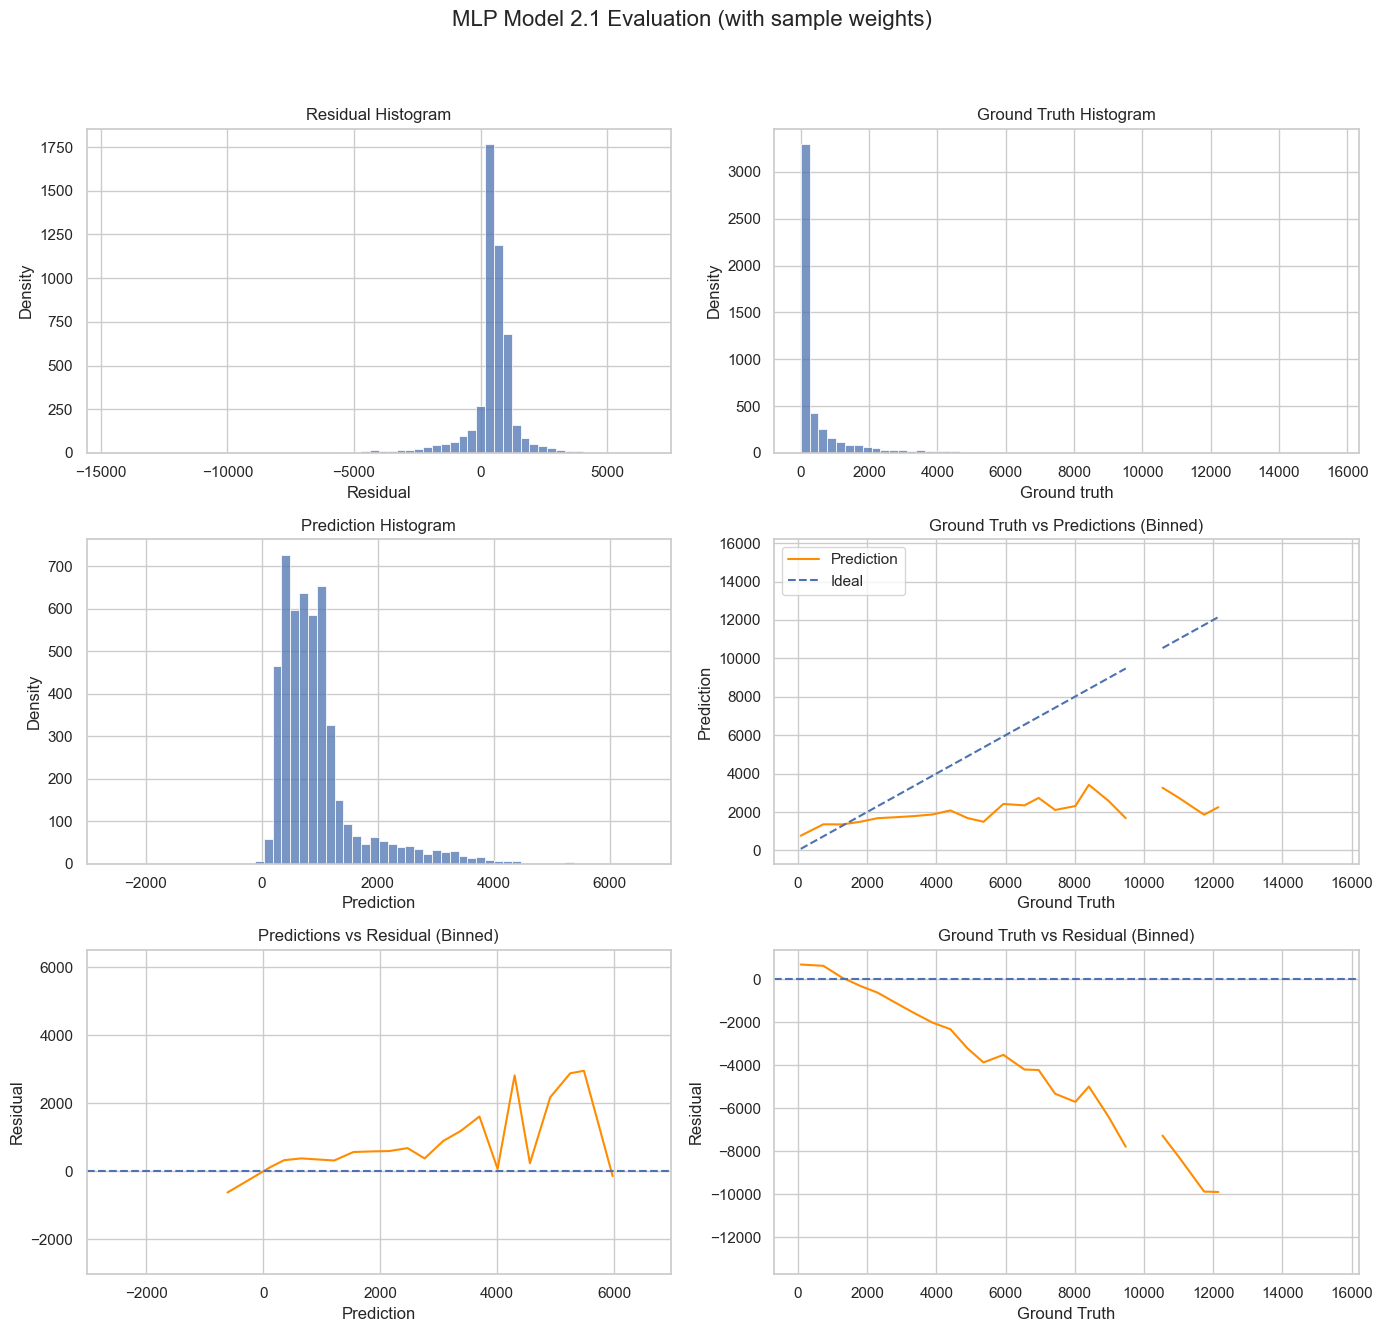

In [147]:
# plot model evaluation
y_pred2_1 = model2_1.predict(X_test_2_1)
plot_model_evaluation(y_test_2_1, y_pred2_1, title="MLP Model 2.1 Evaluation (with sample weights)")

#### Emphasize the weights on the tail more

In [207]:
# compute inverse frequency weights of years
train_sw_df = train_df.copy()
train_sw_df["REMAINING_LIFETIME_YEARS"] = (train_sw_df["REMAINING_LIFETIME"] / 365).round(0).astype(int)
year_freq = train_sw_df["REMAINING_LIFETIME_YEARS"].value_counts()
year_freq = year_freq / len(train_sw_df) # normalize to get frequency proportion

sample_weights = train_sw_df["REMAINING_LIFETIME_YEARS"].map(lambda y: 1 / year_freq[y] * 100).values
sample_weights = np.log1p(sample_weights) # compress extremes
sample_weights = sample_weights / sample_weights.mean() # normalize

# drop column 
train_sw_df.drop(columns=['REMAINING_LIFETIME_YEARS'], inplace=True)

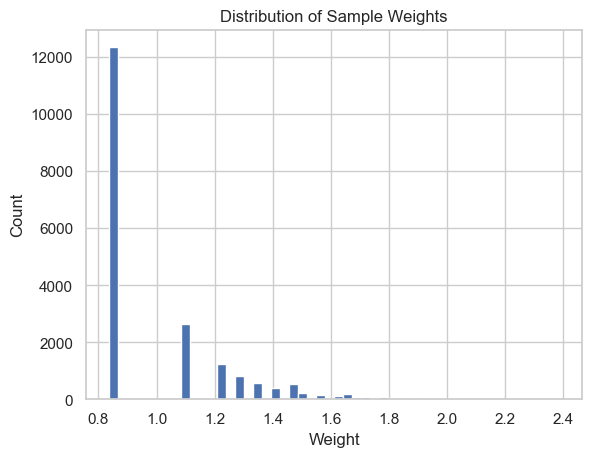

In [208]:
# visualize distribution of sample weights
import matplotlib.pyplot as plt
plt.hist(sample_weights, bins=50)
plt.title("Distribution of Sample Weights")
plt.xlabel("Weight")
plt.ylabel("Count")
plt.show()

In [209]:
# define features and labels for this model
X_train_2_1 = train_sw_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_train_2_1 = train_sw_df["REMAINING_LIFETIME"]

X_test_2_1 = test_df.drop(columns=["LIFETIME", "REMAINING_LIFETIME"])
y_test_2_1 = test_df["REMAINING_LIFETIME"]

In [ ]:
# define model architecture 
model2_1 = keras.Sequential([
    layers.Input(shape=(X_train_2_1.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="linear")  
])

In [211]:
# compile model
model2_1.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[keras.metrics.RootMeanSquaredError()]
)

In [212]:
# train model
early_stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model2_1.fit(
    X_train_2_1, y_train_2_1,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1, 
    sample_weight=sample_weights # specify sample weight array
)

Epoch 1/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 2958970.5000 - root_mean_squared_error: 1336.1309 - val_loss: 2787427.5000 - val_root_mean_squared_error: 1303.8237
Epoch 2/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 783us/step - loss: 2858279.7500 - root_mean_squared_error: 1303.5447 - val_loss: 2781447.0000 - val_root_mean_squared_error: 1303.3042
Epoch 3/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 670us/step - loss: 3048231.2500 - root_mean_squared_error: 1339.0305 - val_loss: 2747517.7500 - val_root_mean_squared_error: 1255.7212
Epoch 4/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 920us/step - loss: 2842000.2500 - root_mean_squared_error: 1297.1879 - val_loss: 2764884.7500 - val_root_mean_squared_error: 1297.7849
Epoch 5/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 2823898.7500 - root_mean_squared_error: 1297.5518 - val_loss: 2746080.0000 - val_root_mean_squared_error: 1239.1849
Epoch 6/100
489/489 ━━━━━━━━━━━━━━━━━━━━ 0s 994us/step - loss: 2684366.2500 - root_mean_squared_error: 1274.8

In [213]:
# evaluate model
loss, rmse = model2_1.evaluate(X_test_2_1, y_test_2_1)
print("Test RMSE:", rmse)

153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 468us/step - loss: 1301517.0000 - root_mean_squared_error: 1138.9492
Test RMSE: 1115.963623046875


153/153 ━━━━━━━━━━━━━━━━━━━━ 0s 413us/step


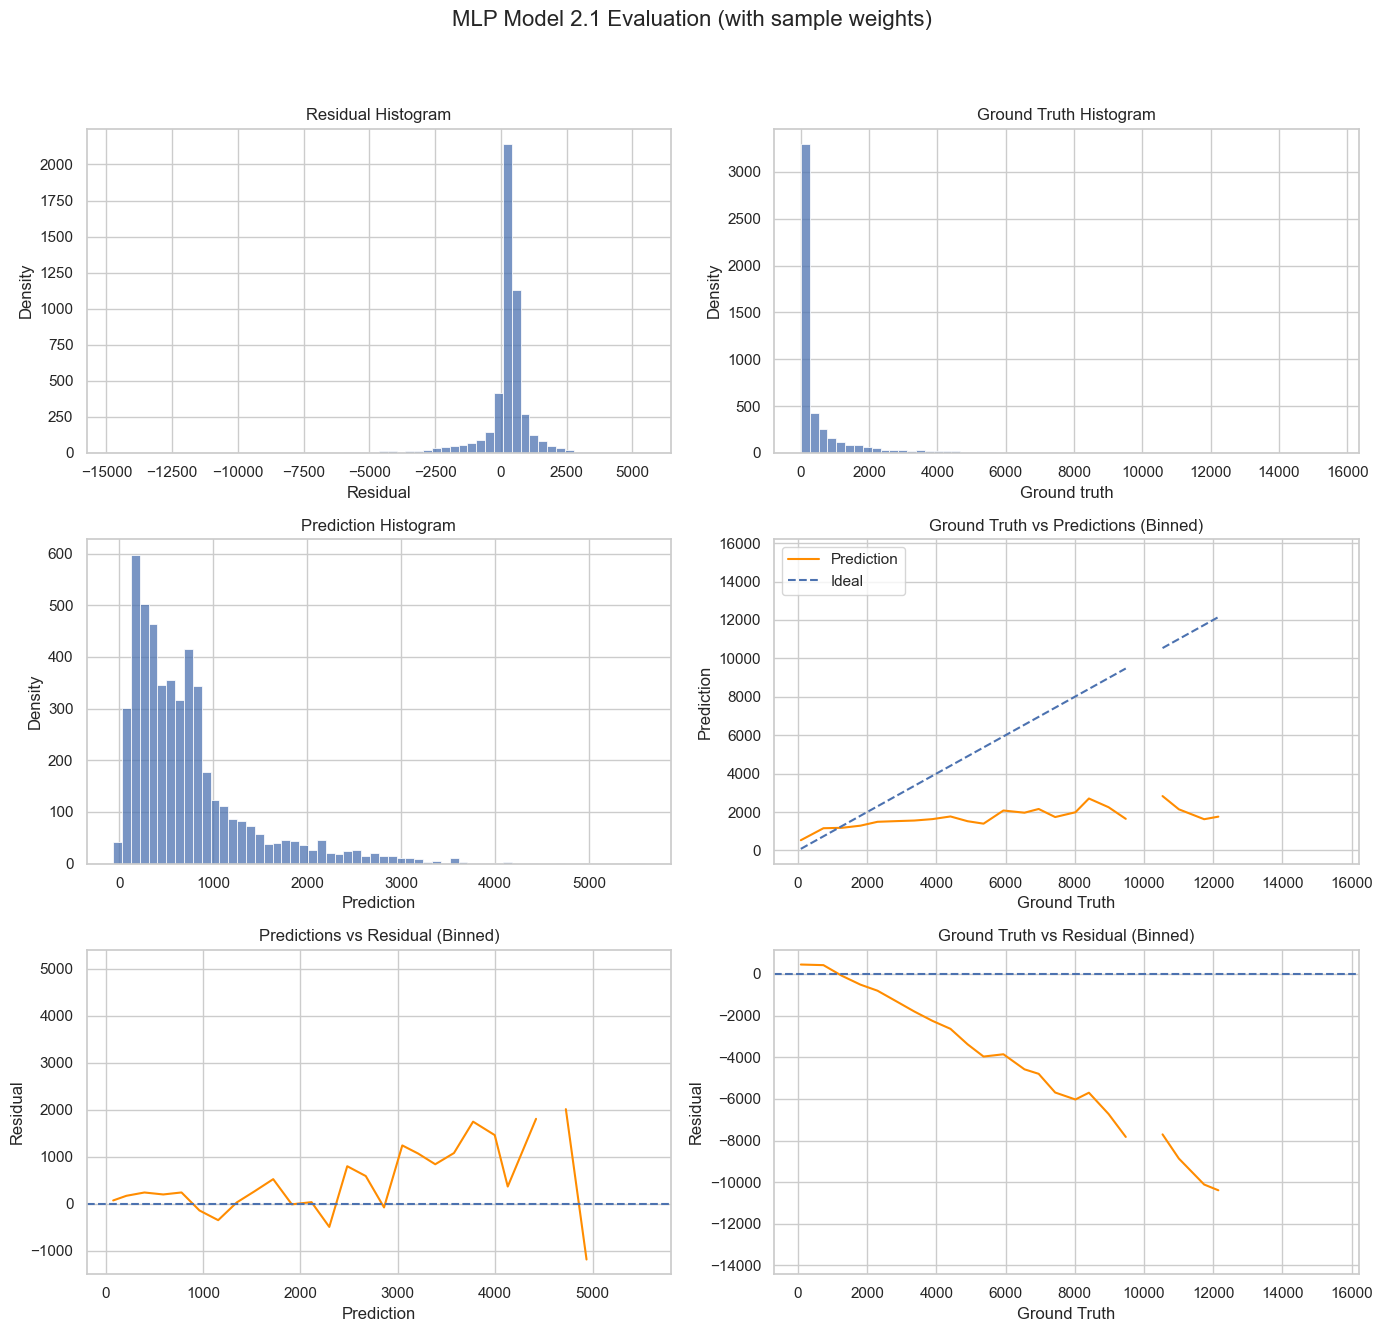

In [214]:
# plot model evaluation
y_pred2_1 = model2_1.predict(X_test_2_1)
plot_model_evaluation(y_test_2_1, y_pred2_1, title="MLP Model 2.1 Evaluation (with sample weights)")

In [215]:
# save model
model2_1.save("../Models/MLP2_1.keras")

### Model 2.2 - SMOTE (smogn)

In [243]:
# load oversampled data with one hot encoding
train_smogn_df = pd.read_csv('../Data/TrainBalancedOHE.csv')
test_smogn_df = pd.read_csv('../Data/TestBalancedOHE.csv')

In [244]:
# define features and labels for this model
X_train_2_2 = train_smogn_df.drop(columns=["REMAINING_LIFETIME"]) # Lifetime is not in dataset
y_train_2_2 = train_smogn_df["REMAINING_LIFETIME"]

X_test_2_2 = test_smogn_df.drop(columns=["REMAINING_LIFETIME"])
y_test_2_2 = test_smogn_df["REMAINING_LIFETIME"]

In [248]:
# define model architecture 
model2_2 = keras.Sequential([
    layers.Input(shape=(X_train_2_2.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="linear")  
])

In [249]:
# compile model
model2_2.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=[keras.metrics.RootMeanSquaredError()]
)

In [250]:
# train model
early_stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

history = model2_2.fit(
    X_train_2_2, y_train_2_2,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1, 
)

Epoch 1/100
726/726 ━━━━━━━━━━━━━━━━━━━━ 1s 797us/step - loss: 4501901.5000 - root_mean_squared_error: 2112.9504 - val_loss: 2543841.2500 - val_root_mean_squared_error: 1594.9424
Epoch 2/100
726/726 ━━━━━━━━━━━━━━━━━━━━ 1s 697us/step - loss: 2635097.2500 - root_mean_squared_error: 1620.9980 - val_loss: 2449454.2500 - val_root_mean_squared_error: 1565.0732
Epoch 3/100
726/726 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 2342731.2500 - root_mean_squared_error: 1529.5834 - val_loss: 2395272.5000 - val_root_mean_squared_error: 1547.6667
Epoch 4/100
726/726 ━━━━━━━━━━━━━━━━━━━━ 1s 717us/step - loss: 2325373.0000 - root_mean_squared_error: 1523.8362 - val_loss: 2347978.7500 - val_root_mean_squared_error: 1532.3115
Epoch 5/100
726/726 ━━━━━━━━━━━━━━━━━━━━ 1s 699us/step - loss: 2462172.2500 - root_mean_squared_error: 1567.9609 - val_loss: 2292830.2500 - val_root_mean_squared_error: 1514.2095
Epoch 6/100
726/726 ━━━━━━━━━━━━━━━━━━━━ 1s 709us/step - loss: 2298661.5000 - root_mean_squared_error: 1514

In [251]:
# evaluate model
loss, rmse = model2_2.evaluate(X_test_2_2, y_test_2_2)
print("Test RMSE:", rmse)

227/227 ━━━━━━━━━━━━━━━━━━━━ 0s 790us/step - loss: 1807961.8750 - root_mean_squared_error: 1341.8937
Test RMSE: 1325.6212158203125


227/227 ━━━━━━━━━━━━━━━━━━━━ 0s 502us/step


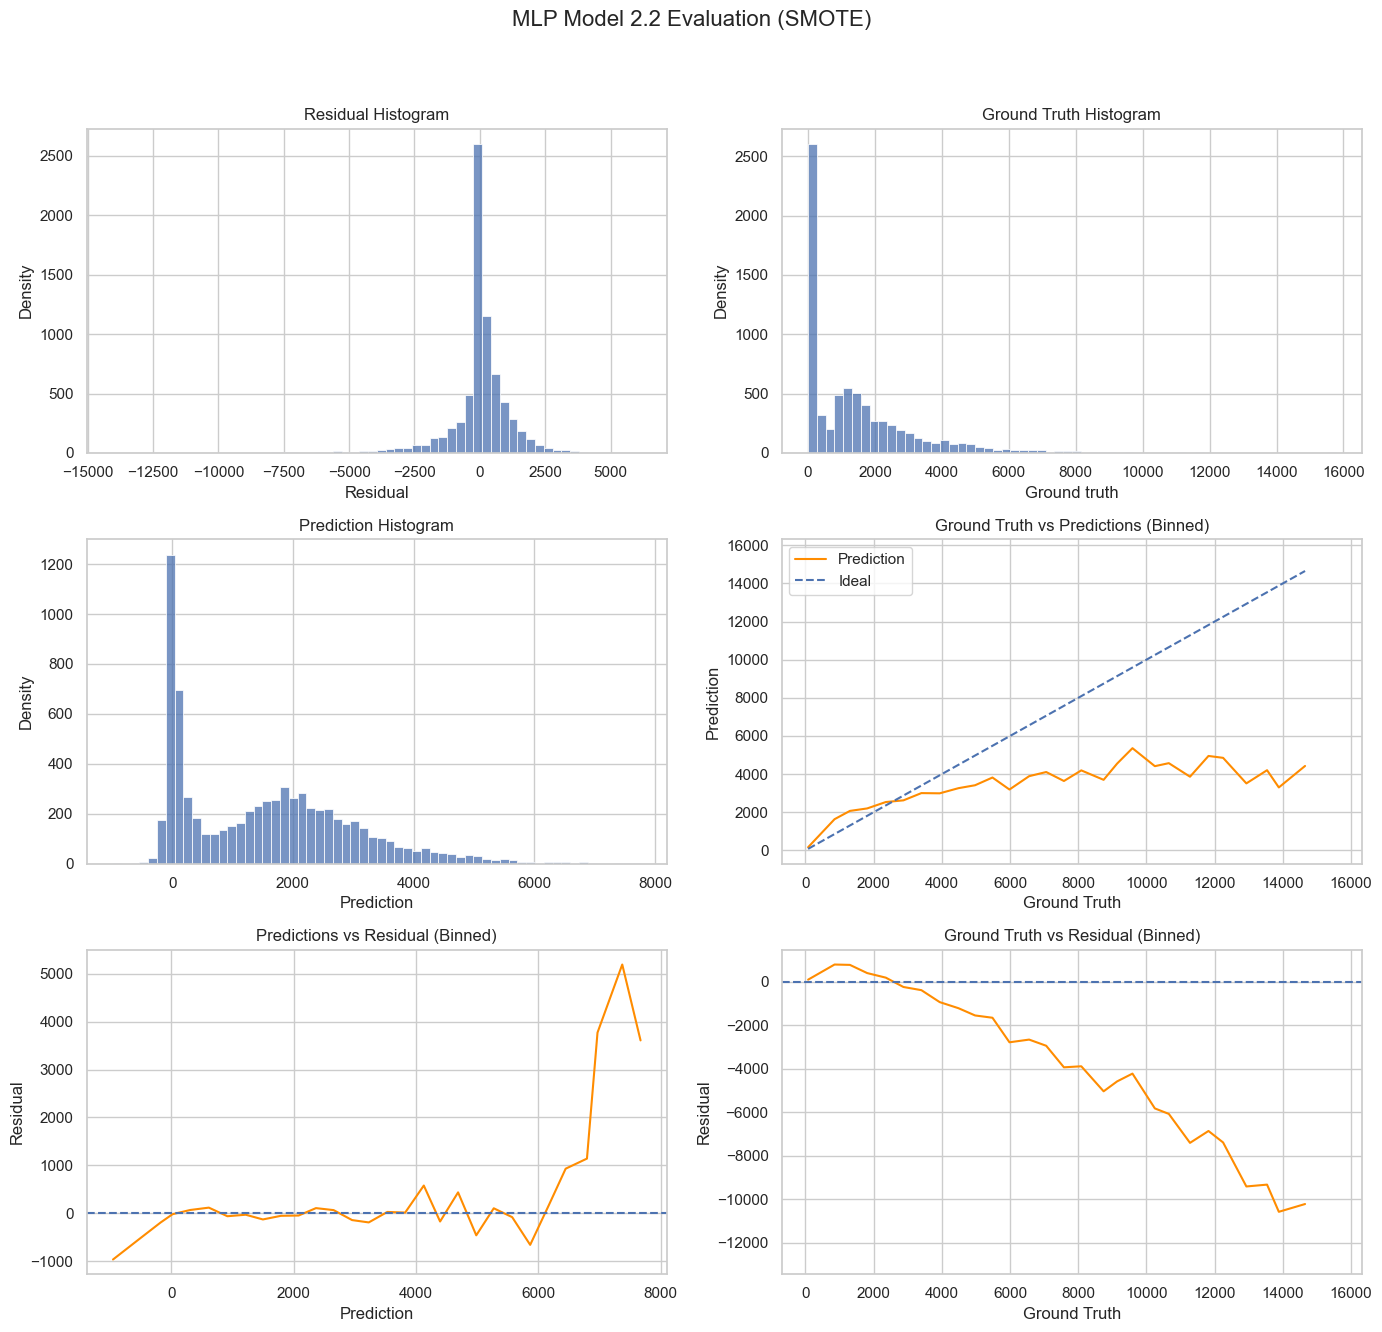

In [252]:
# plot model evaluation
y_pred2_2 = model2_2.predict(X_test_2_2)
plot_model_evaluation(y_test_2_2, y_pred2_2, title="MLP Model 2.2 Evaluation (SMOTE)")

In [253]:
# save model
model2_2.save("../Models/MLP2_2.keras")